# Pando: TF x binding-site regulatory networks

[Pando](https://github.com/quadbio/Pando) (Fleck *et al.*, *Nature* 2023) infers a gene regulatory network from paired single-cell RNA and ATAC data. For each target gene it

1. takes the peaks near the gene (here 100 kb upstream plus the gene body) that carry a TF motif,
2. keeps the peaks and the TFs whose activity correlates with the gene,
3. fits `gene ~ sum(peak x TF)`: the gene's expression regressed on TF expression times the accessibility of that TF's binding site,

and reads the significant TF–peak terms as regulatory links. TFs whose links point to many genes form TF *modules*.

`epi.grn.pando` runs the omicverse port [py-Pando](https://github.com/omicverse/py-Pando) (`pip install 'epione[pando]'`) on Epione objects. py-Pando is parity-tested against R Pando 1.1.1: candidate regions, motif matches, the glm network and its modules are identical to R's on a 10x multiome fixture (see its reconstruction report). This tutorial uses the same human cerebellum multiome data as the SCENIC+ tutorials and ends with a comparison against SCENIC+ eRegulons on the same cells.

In [1]:
import os
import tarfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import pooch
import matplotlib.pyplot as plt

import epione as epi
import pypando as pp

pooch.get_logger().setLevel("WARNING")
sc.settings.verbosity = 0
DATA = Path(os.environ.get("EPIONE_DATA_DIR", pooch.os_cache("epione"))) / "scenicplus_cerebellum"
DATA.mkdir(parents=True, exist_ok=True)

## Data: 10x multiome human cerebellum (3k cells)

The 10x Genomics `human_brain_3k` multiome sample with the cell-type labels from the SCENIC+ tutorial, as in [SCENIC+ 4](t_scenic_egrn.ipynb).

In [2]:
tar = pooch.retrieve(
    "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/human_brain_3k/"
    "human_brain_3k_filtered_feature_bc_matrix.tar.gz",
    known_hash="sha256:81a386c1f733e48d8fa6026e334e288333b2ad5586f9d4088bfe8b7528996fd4",
    path=DATA, progressbar=False)
cell_tsv = pooch.retrieve(
    "https://raw.githubusercontent.com/aertslab/pycisTopic/polars/data/cell_data_human_cerebellum.tsv",
    known_hash="sha256:e762f44f1a6523614c019419bf8971da536bba72ca5a0322d0e1b215f863a56c",
    path=DATA, progressbar=False)
mtx_dir = DATA / "filtered_feature_bc_matrix"
if not (mtx_dir / "matrix.mtx.gz").exists():
    with tarfile.open(tar) as t:
        t.extractall(DATA, filter="data")

both = sc.read_10x_mtx(mtx_dir, gex_only=False)
cell_data = pd.read_table(cell_tsv, index_col=0)
cell_data.index = cell_data.index.str.replace("-10x_multiome_brain", "", regex=False)
cells = both.obs_names.intersection(cell_data.index)
both = both[cells].copy()
rna = both[:, both.var["feature_types"] == "Gene Expression"].copy()
atac = both[:, both.var["feature_types"] == "Peaks"].copy()
rna.var_names_make_unique()
for a in (rna, atac):
    a.obs["cell_type"] = cell_data.loc[a.obs_names, "Seurat_cell_type"].astype("category")
print(rna, atac, sep="\n")

AnnData object with n_obs × n_vars = 2313 × 36601
    obs: 'cell_type'
    var: 'gene_ids', 'feature_types'
AnnData object with n_obs × n_vars = 2313 × 134030
    obs: 'cell_type'
    var: 'gene_ids', 'feature_types'


## Inputs

Pando reads Seurat's log-normalised expression and Signac's TF-IDF peak matrix. `scanpy`'s `normalize_total(target_sum=1e4)` + `log1p` is Seurat's `LogNormalize`; the ATAC matrix stays as counts and `epi.grn.pando` applies Signac's TF-IDF itself.

The target genes are the 300 most variable genes. Pando's runtime grows with the number of targets and with the number of TF–peak terms per gene.

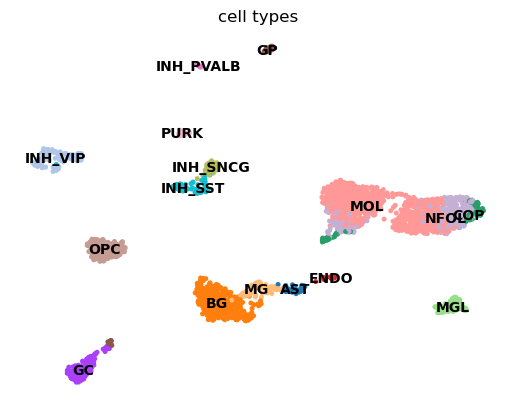

In [3]:
rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=4000)
sc.pp.pca(rna, n_comps=30, mask_var="highly_variable")
sc.pp.neighbors(rna, n_pcs=30)
sc.tl.umap(rna)
targets = rna.var.sort_values("dispersions_norm", ascending=False).index[:300].tolist()
sc.pl.umap(rna, color="cell_type", legend_loc="on data", frameon=False, title="cell types")

## Run Pando

`epi.grn.pando` runs py-Pando's `initiate_grn` → `find_motifs` → `infer_grn` → `find_modules` with Pando's defaults: candidate regions are peaks minus exons, motifs are Pando's bundled collection (1,590 JASPAR 2020 + CIS-BP motifs), and the model is a Gaussian glm with `peak:TF` interaction terms. The gene annotation comes from Epione's hg38 GENCODE GFF3, built the way Signac's `GetGRangesFromEnsDb` builds it.

By default only the candidate regions a target gene can reach are scanned for motifs, against the base composition of all candidate regions (`scan="near_targets"`). Each region is scanned independently given that background, and regions are assigned to genes one at a time, so the network is the same as with `scan="all"`, which scans all ~100k peaks as Pando does.

In [4]:
%%time
grn = epi.grn.pando(rna, atac, genome="hg38", genes=targets, method="glm", verbose=False)
grn

CPU times: user 1min 36s, sys: 2.39 s, total: 1min 38s
Wall time: 1min 39s


A RegulatoryNetwork object based on 1136 transcription factors

1 inferred network: glm_network

## Coefficients and model fit

One row per TF–region term in a gene's model: the estimate, its standard error, t statistic, p value and FDR across all terms, plus the TF–gene correlation.

In [5]:
coefs = pp.coef(grn)
fit = pp.gof(grn)
print(f"{fit.shape[0]} target genes with a model, {len(coefs):,} TF-region terms, "
      f"{(coefs.padj < 0.05).sum():,} with FDR < 0.05")
coefs.sort_values("padj").head(10)

264 target genes with a model, 33,853 TF-region terms, 3,122 with FDR < 0.05


,tf,target,region,term,estimate,std_err,statistic,pval,padj,corr
26759,HES2,LMAN1L,chr15-74789956-74790816,HES2:chr15_74789956_74790816,0.688306,0.004725,145.684617,0.000000e+00,0.000000e+00,0.816546
23094,TBX18,ADGRD1,chr12-130915995-130916851,chr12_130915995_130916851:TBX18,1.043511,0.026587,39.248498,3.147758e-255,5.369603e-251,0.536463
14173,TWIST2,SERPINE1,chr7-101126520-101127103,chr7_101126520_101127103:TWIST2,1.269029,0.047676,26.617904,4.943842e-136,3.373381e-132,0.206389
32384,KLF4,MX2,chr21-41362056-41362624,chr21_41362056_41362624:KLF4,0.235608,0.009017,26.128194,6.783892e-132,3.857434e-128,0.261081
23103,LEF1,ADGRD1,chr12-130932356-130932926,chr12_130932356_130932926:LEF1,-0.932338,0.040007,-23.304192,2.008453e-107,7.613600e-104,0.525242
11984,CREB3L2,TBX18,chr6-84764599-84765113,chr6_84764599_84765113:CREB3L2,0.141952,0.006383,22.239787,2.254751e-99,6.993212e-96,0.194141
11987,EGR1,TBX18,chr6-84773331-84774215,EGR1:chr6_84773331_84774215,0.340364,0.015728,21.640425,1.207188e-94,3.432135e-91,0.170876
23145,EBF1,ADGRD1,chr12-131002029-131002921,EBF1:chr12_131002029_131002921,1.601498,0.075543,21.199760,7.910232e-91,1.927667e-87,0.569968
15679,TCF3,ESCO2,chr8-27709244-27710174,TCF3:chr8_27709244_27710174,0.225028,0.010756,20.921647,4.271464e-89,9.715303e-86,0.103054
19911,CEBPD,PDLIM1,chr10-95247367-95247884,chr10_95247367_95247884:CEBPD,0.427228,0.020789,20.551029,4.772110e-86,9.577064e-83,0.145109


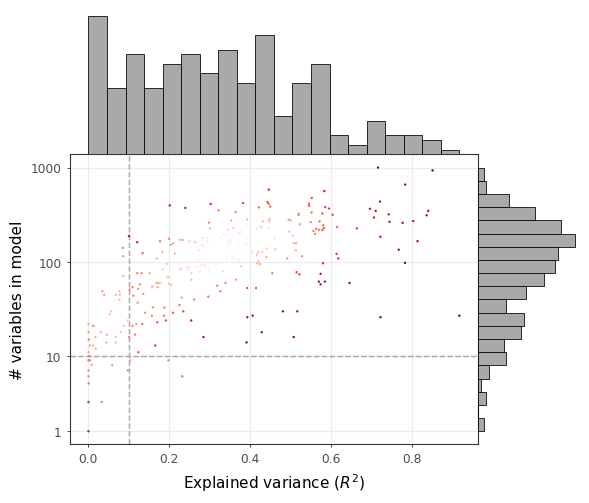

In [6]:
fig = pp.plot_gof(grn)

Genes with many variables can reach a high $R^2$ partly by overfitting; `find_modules` therefore only uses models with $R^2 > 0.1$ and more than 10 variables (Pando's defaults).

## TF modules

A TF's positive (negative) module is the set of genes it has significant positive (negative) terms for, kept when it has more than 5 genes.

In [7]:
mods = pp.NetworkModules(grn)
meta = mods.meta
pos = mods.features["genes_pos"]
neg = mods.features["genes_neg"]
size = pd.DataFrame({"positive": pd.Series({k: len(v) for k, v in pos.items()}),
                     "negative": pd.Series({k: len(v) for k, v in neg.items()})}).fillna(0).astype(int)
size = size.sort_values("positive", ascending=False)
print(f"{len(pos)} positive and {len(neg)} negative modules")
size.head(15)

95 positive and 32 negative modules


,positive,negative
BNC2,42,16
RUNX1,38,8
IKZF1,33,11
ZNF267,33,9
ARID3A,32,11
RREB1,30,12
NFATC2,27,6
JAZF1,27,6
MEF2C,26,0
ZNF618,25,15


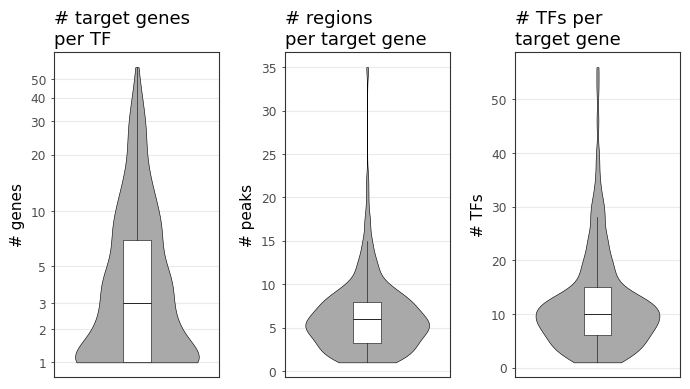

In [8]:
fig = pp.plot_module_metrics(grn)

**Module activity per cell type.** For each of the 20 largest positive modules, the mean log-normalised expression of its genes, averaged per cell type and then scaled across cell types (one row per module, z-score over the 16 cell types). The colour range is symmetric and covers the largest value, so nothing is clipped. A module is cell-type specific when its genes are, which is how Pando modules are usually read.

The largest modules are microglial (MGL): the 300 targets were chosen by expression dispersion, which favours markers of rare cell types, and microglia make up only 3% of these cells, so their markers are among the most dispersed genes and the immune TFs that regulate them (RUNX1, IKZF1, SPI1, ...) collect the biggest modules.

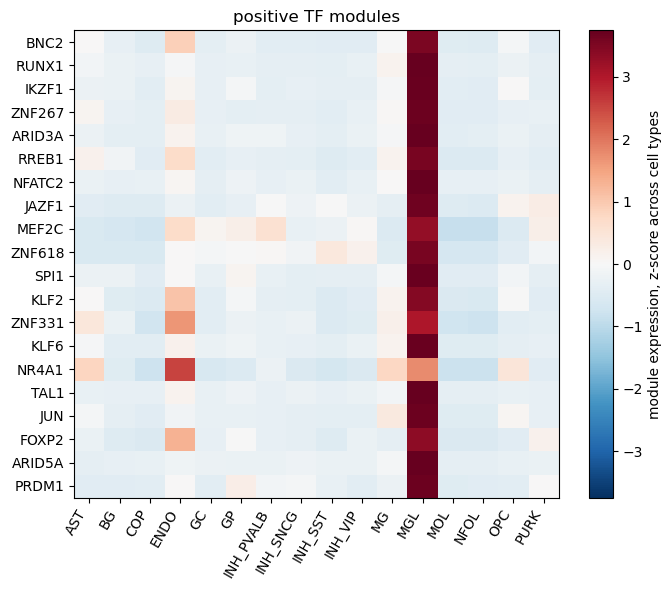

In [9]:
top = size.index[:20]
X = pd.DataFrame(rna.X.toarray(), index=rna.obs_names, columns=rna.var_names)   # log-normalised
ct = rna.obs["cell_type"]
score = pd.DataFrame({tf: X[pos[tf]].mean(axis=1) for tf in top})                 # module score per cell
act = score.groupby(ct.to_numpy()).mean().T                                        # modules x cell types
act = act.sub(act.mean(axis=1), axis=0).div(act.std(axis=1), axis=0)              # scale each row
lim = float(np.abs(act.to_numpy()).max())
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(act.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(act)), act.index)
ax.set_xticks(range(act.shape[1]), act.columns, rotation=60, ha="right")
fig.colorbar(im, ax=ax, label="module expression, z-score across cell types")
ax.set_title("positive TF modules")
fig.tight_layout()

## Module graph

`get_network_graph` builds the TF → target graph of the modules with PageRank centrality, and lays the genes out with UMAP on their co-expression weighted by the regulatory coefficients (Pando's `umap_method = "weighted"`). The layout uses umap-learn, so coordinates differ from R's `uwot`; the graph and the centralities do not.

158 genes, 251 edges


,name,centrality,UMAP_1,UMAP_2
94,LMAN1L,0.010283,10.016044,2.225176
31,FLT1,0.008474,11.422225,3.305124
145,PDLIM1,0.007921,6.770357,1.216614
118,ABCB1,0.007921,10.530216,2.460822
146,SLC2A3,0.007921,11.908620,3.570819
126,DPYSL3,0.007663,9.873244,2.382791
21,CD74,0.007247,14.484595,8.707559
70,COL4A1,0.007226,6.091079,0.677276
127,FSTL5,0.007190,10.503340,1.805332
125,CXCL14,0.007190,9.963712,2.223018


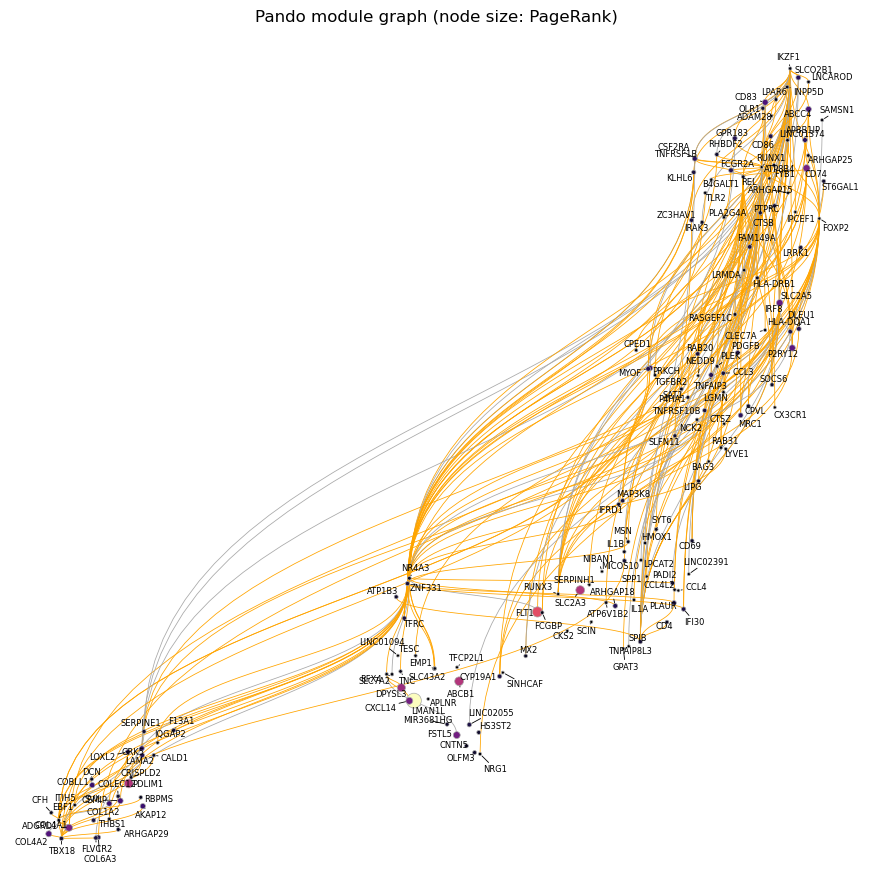

In [10]:
pp.get_network_graph(grn, umap_method="weighted")
g = pp.NetworkGraph(grn)
print(f"{len(g['nodes'])} genes, {len(g['edges'])} edges")
fig, ax = plt.subplots(figsize=(11, 11))
pp.plot_network_graph(grn, text_size=6, ax=ax)
ax.set_title("Pando module graph (node size: PageRank)");
g["nodes"].sort_values("centrality", ascending=False).head(10)

## Comparison with SCENIC+

SCENIC+ builds eRegulons differently: a TF's cistrome comes from motif enrichment in cell-type-specific region sets, region–gene and TF–gene links come from correlations over metacells, and an eRegulon keeps the TF–region–gene triplets that agree. The next cells build SCENIC+ eRegulons on the same cells with exactly the inputs of [SCENIC+ 4](t_scenic_egrn.ipynb) (cistromes from JASPAR 2020 motif enrichment, correlation-based links), then compare them with Pando's modules: which TFs each method finds, and, for TFs found by both, how many target genes they share. Only the 300 genes Pando modelled are compared.

In [11]:
%%time
import contextlib, io, warnings
from scipy import sparse
from scipy.stats import hypergeom

with warnings.catch_warnings(), contextlib.redirect_stderr(io.StringIO()):
    warnings.simplefilter("ignore")
    epi.tl.add_motif_matrix(atac, genome_fasta=str(epi.utils.genome.hg38.fasta),
                            motif_db="JASPAR2020", verbose=False)
motif_names = np.asarray(atac.uns["motif_names"])
M = sparse.csc_matrix(atac.varm["motif"]).astype(np.int64)
acc = sparse.csr_matrix(atac.X > 0).astype(np.float32)
n = acc.shape[0]
tot = np.asarray(acc.sum(0)).ravel()
region_sets = {}
for c in ct.cat.categories:
    sel = (ct == c).to_numpy()
    fg = np.asarray(acc[sel].sum(0)).ravel()
    frac, rest = fg / sel.sum(), (tot - fg) / (n - sel.sum())
    score = np.log2((frac + 0.01) / (rest + 0.01))
    score[frac < 0.05] = -np.inf
    region_sets[c] = np.argsort(-score)[:3000]
K = np.asarray(M.sum(0)).ravel()
cis_hits = {}
for c, idx in region_sets.items():
    k = np.asarray(M[idx].sum(0)).ravel()
    p = hypergeom.sf(k - 1, M.shape[0], K, len(idx))
    fold = (k / len(idx)) / np.maximum(K / M.shape[0], 1e-12)
    for j in np.flatnonzero((p < 1e-6) & (fold > 1.5)):
        hit = idx[M[idx, j].toarray().ravel() > 0]
        cis_hits.setdefault(j, set()).update(hit.tolist())
pb = X.groupby(ct.to_numpy()).mean()
expressed = set(pb.columns[(pb > 0.2).any(axis=0)])
tf_motifs, tf_peaks = {}, {}
for j, peaks in cis_hits.items():
    for tf in motif_names[j].split("_", 1)[-1].upper().split("::"):
        if tf in expressed:
            tf_motifs.setdefault(tf, []).append(motif_names[j])
            tf_peaks.setdefault(tf, set()).update(peaks)
tfs = sorted(tf_peaks)
cis = np.zeros((atac.n_vars, len(tfs)), dtype=bool)
for t, tf in enumerate(tfs):
    cis[list(tf_peaks[tf]), t] = True
cistromes = sc.AnnData(X=cis, obs=pd.DataFrame(index=atac.var_names),
                       var=pd.DataFrame({"motifs": [",".join(tf_motifs[t]) for t in tfs]}, index=tfs))

genes_ann = epi.utils.get_gene_annotation(epi.utils.genome.hg38)
atac.obsm["X_pca"] = rna.obsm["X_pca"]
p2g = epi.tl.peak_to_gene(atac, rna=rna, gene_annotation=genes_ann, use_rep="X_pca", n_metacells=300,
                          k_neighbors=50, max_distance=150_000, seed=0, inplace=False, verbose=False)
p2g = p2g.dropna(subset=["correlation"])
r2g = pd.DataFrame({"target": p2g["gene"].to_numpy(), "region": p2g["peak"].to_numpy(),
                    "importance": p2g["correlation"].abs().to_numpy(), "rho": p2g["correlation"].to_numpy()})
r2g["importance_x_rho"] = r2g["importance"] * r2g["rho"]
r2g["importance_x_abs_rho"] = r2g["importance"] * r2g["rho"].abs()

rng = np.random.default_rng(0)
anchors = rng.choice(rna.n_obs, 300, replace=False)
dist = ((rna.obsm["X_pca"][anchors, None, :] - rna.obsm["X_pca"][None, :, :]) ** 2).sum(-1)
knn = np.argsort(dist, axis=1)[:, :50]
keep_genes = rna.var_names[rna.var["highly_variable"] | rna.var_names.isin(tfs)]
Xk = rna[:, keep_genes].X.toarray()
metac = np.stack([Xk[k].mean(0) for k in knn])
metac = (metac - metac.mean(0)) / (metac.std(0) + 1e-12)
cor = metac.T @ metac / metac.shape[0]
gi = pd.Index(keep_genes)
tf2g = pd.concat([pd.DataFrame({"TF": tf, "target": keep_genes, "importance": np.abs(cor[gi.get_loc(tf)]),
                                "rho": cor[gi.get_loc(tf)]}) for tf in tfs], ignore_index=True)
tf2g = tf2g[tf2g["TF"] != tf2g["target"]]
tf2g["regulation"] = np.sign(tf2g["rho"]).astype(int)
tf2g = tf2g[["TF", "target", "importance", "regulation", "rho"]].reset_index(drop=True)
eregulons = epi.scenic.build_egrn(tf2g, r2g, cistromes, is_extended=False, min_target_genes=10)
print(f"{eregulons.eRegulon_name.nunique()} SCENIC+ eRegulons, {len(eregulons):,} TF-region-gene links")

108 SCENIC+ eRegulons, 10,256 TF-region-gene links
CPU times: user 2min 42s, sys: 2.61 s, total: 2min 45s
Wall time: 2min 40s


TFs with targets among the 300 genes: Pando 101, SCENIC+ 57, both 18
median Jaccard 0.078 (shuffled: 0.030)


,Jaccard
IKZF1,0.326087
RUNX1,0.318841
SPI1,0.250000
ETS2,0.225806
ELF1,0.157143
NFIA,0.111111
FLI1,0.111111
SMAD3,0.108108
FOS,0.081081
JUNB,0.074074


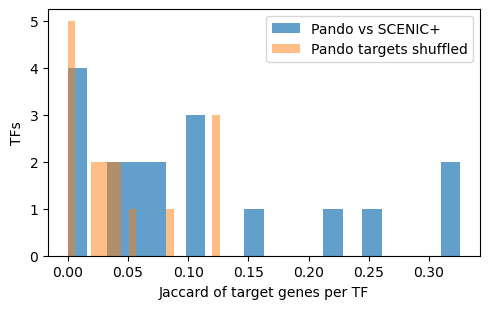

In [12]:
tset = set(targets)
sp_tf = {}
for tf, sub in eregulons.groupby("TF"):
    genes_tf = set(sub["Gene"]) & tset
    if genes_tf:
        sp_tf[tf] = genes_tf
pa_tf = {}
for d in (pos, neg):
    for tf, g in d.items():
        pa_tf.setdefault(tf, set()).update(set(g) & tset)
shared = sorted(set(sp_tf) & set(pa_tf))
print(f"TFs with targets among the 300 genes: Pando {len(pa_tf)}, SCENIC+ {len(sp_tf)}, both {len(shared)}")
jac = pd.Series({tf: len(sp_tf[tf] & pa_tf[tf]) / len(sp_tf[tf] | pa_tf[tf]) for tf in shared}).sort_values(ascending=False)
# expected overlap if Pando's targets were random genes of the same number
rng = np.random.default_rng(1)
null = []
for tf in shared:
    k = len(pa_tf[tf])
    r = set(rng.choice(targets, k, replace=False))
    null.append(len(sp_tf[tf] & r) / len(sp_tf[tf] | r))
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(jac, bins=20, alpha=0.7, label="Pando vs SCENIC+")
ax.hist(null, bins=20, alpha=0.5, label="Pando targets shuffled")
ax.set_xlabel("Jaccard of target genes per TF"); ax.set_ylabel("TFs"); ax.legend()
fig.tight_layout()
print(f"median Jaccard {jac.median():.3f} (shuffled: {np.median(null):.3f})")
jac.head(15).to_frame("Jaccard")

The overlap is real but modest. Of 101 TFs with Pando targets among the 300 genes and 57 with SCENIC+ targets, 18 are found by both; for those, the median Jaccard of their target genes is 0.078, against 0.030 when Pando's targets are replaced by random genes of the same number. Agreement is best for IKZF1, RUNX1 and SPI1 (Jaccard 0.25–0.33) and weakest for the AP-1 family (FOS, JUN, FOSB, FOSL2 below 0.1), whose broad motifs are enriched in most region sets.

The two methods define a link very differently: Pando requires the TF x peak term to explain the gene's expression in a joint regression, while SCENIC+ requires the TF's motif to be enriched in a cell-type region set and the TF–gene and region–gene correlations to agree. Neither is ground truth here. Use the overlap as a confidence filter rather than as validation of either.

## A TF sub-network

`get_tf_network` follows the module graph outwards from one TF. Along the shortest paths, a target is reached either directly or through other TFs. For each target it keeps:
- the direct edge;
- the most significant indirect path, i.e. the path with the largest mean $-\log_{10}$ adjusted p-value (`keep_all_edges=True` keeps every shortest path).

`plot_tf_network` draws the result as a circular tree:
- the root is the TF;
- each ring is one step further away;
- edges are coloured by sign: orange activating, grey repressing.

Only TFs that are themselves modelled target genes keep their outgoing edges in the module graph, so only they can root or relay a sub-network. The cell takes the first of the best-agreeing TFs (SPI1, IKZF1, RUNX1) that has outgoing edges. SPI1 has none here, so the root is IKZF1, the TF on which Pando and SCENIC+ agree most (Jaccard 0.33).

py-Pando's default keeps the most significant path. In R Pando 1.1.1 the default silently keeps the path with the largest mean coefficient instead, because of a column-name bug, and it ignores `order`. py-Pando fixes both. With `keep_all_edges=True, order=np.inf` it returns exactly R's graph; see the [py-Pando changelog](https://github.com/omicverse/py-Pando/blob/main/CHANGELOG.md).

root: IKZF1
74 targets: 44 direct, 30 only through other TFs; 104 edge rows over 74 distinct edges


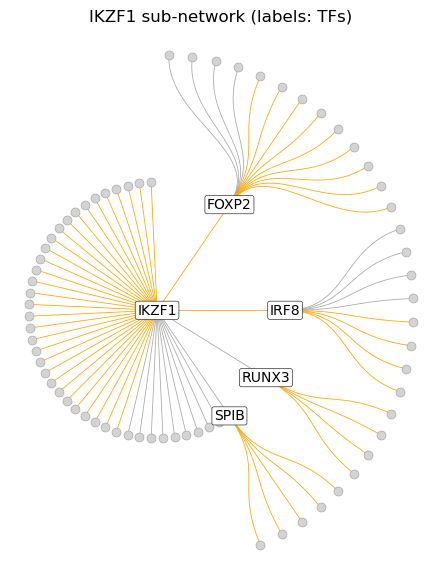

In [13]:
edges = pp.NetworkGraph(grn)["edges"]
relays = set(edges["from_node"])
tf = None
for cand in ("SPI1", "IKZF1", "RUNX1"):
    if cand in relays:
        try:
            pp.get_tf_network(grn, tf=cand, verbose=False)
            tf = cand
            break
        except ValueError as e:  # fewer than 3 targets
            print(cand, "-", e)
print("root:", tf)
tn = pp.NetworkGraph(grn, graph="tf_graphs")[tf]["edges"]
direct = set(tn.loc[tn["from_node"] == tf, "to_node"])
leaves = set(tn["end_node"])
print(f"{len(leaves)} targets: {len(direct)} direct, {len(leaves - direct)} only through other TFs; "
      f"{len(tn)} edge rows over {len(set(zip(tn.from_node, tn.to_node)))} distinct edges")
fig = pp.plot_tf_network(grn, tf, label_nodes="tfs")
fig.axes[0].set_title(f"{tf} sub-network (labels: TFs)");

In [14]:
# relay TFs: how many targets each passes the signal on to, and with which combined sign
relay = tn[tn["from_node"] != tf]
(relay.groupby("from_node")
      .agg(targets=("end_node", "nunique"), activating=("comb_dir", lambda s: int((s > 0).sum())),
           repressing=("comb_dir", lambda s: int((s < 0).sum())))
      .sort_values("targets", ascending=False))

,targets,activating,repressing
from_node,,,
FOXP2,13,9,4
IRF8,8,4,4
SPIB,5,0,5
RUNX3,4,0,4


IKZF1 reaches 74 of the modelled genes: 44 directly and 30 only through other TFs. Most of the indirect ones go through FOXP2 and IRF8; SPIB and RUNX3 relay only repressive paths. The combined sign of a path is the product of its edge signs, so a repressor of a repressor counts as activating. Paths of length one are kept as they are; each indirect target keeps its single most significant path. Treat the indirect part as a hypothesis about how IKZF1's influence propagates, not as evidence of regulation.

## Notes

* **Parity.** py-Pando reproduces R Pando 1.1.1 on a 10x PBMC multiome fixture (2,000 cells, 150 targets): candidate regions, Signac and GREAT peak-to-gene windows and all 1,240,962 motif matches are identical; the glm network (24,642 terms) matches to ~1e-14 with -log10 p within 4e-13 and identical modules; cv.glmnet reproduces R's folds and coefficients (5e-14); bagging and Bayesian ridge match to ~1e-14; glmnet agrees to Pearson 0.9999 with identical lambdas. For `xgb`, py-Pando uses Pando's parameters (`max_depth = 3, eta = 0.01`); R's xgboost >= 3 silently ignores them in Pando's call, so py-Pando matches R only when they are honoured. See [py-Pando's reconstruction report](https://github.com/omicverse/py-Pando/blob/main/RECONSTRUCTION_REPORT.md).
* **Other models.** `method="glmnet"`, `"cv.glmnet"`, `"xgb"`, `"bagging_ridge"` and `"bayesian_ridge"` are available; `find_modules` supports glm, glmnet and xgb networks. Pando's `brms` models are not ported. `get_tf_network` / `plot_tf_network` need pypando >= 0.1.1.
* **Candidate regions.** Pando can restrict candidate regions to conserved elements or cCREs: `regions=pypando.data.phastcons_hg38()` or `pypando.data.screen_ccre_hg38()` (downloaded on first use).